In [1]:
print("Let's start")

Let's start


In [47]:
import pandas as pd

train = pd.read_csv('/mnt/WindowsD/Artificial Intelligence/MLOPS/projects/trip-duration/data/raw/train.csv')
test = pd.read_csv('/mnt/WindowsD/Artificial Intelligence/MLOPS/projects/trip-duration/data/raw/test.csv')

In [3]:
train.info()

<class 'pandas.DataFrame'>
RangeIndex: 1458644 entries, 0 to 1458643
Data columns (total 11 columns):
 #   Column              Non-Null Count    Dtype  
---  ------              --------------    -----  
 0   id                  1458644 non-null  str    
 1   vendor_id           1458644 non-null  int64  
 2   pickup_datetime     1458644 non-null  str    
 3   dropoff_datetime    1458644 non-null  str    
 4   passenger_count     1458644 non-null  int64  
 5   pickup_longitude    1458644 non-null  float64
 6   pickup_latitude     1458644 non-null  float64
 7   dropoff_longitude   1458644 non-null  float64
 8   dropoff_latitude    1458644 non-null  float64
 9   store_and_fwd_flag  1458644 non-null  str    
 10  trip_duration       1458644 non-null  int64  
dtypes: float64(4), int64(3), str(4)
memory usage: 189.2 MB


In [4]:
train.describe()

,vendor_id,passenger_count,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,trip_duration
count,1.458644e+06,1.458644e+06,1.458644e+06,1.458644e+06,1.458644e+06,1.458644e+06,1.458644e+06
mean,1.534950e+00,1.664530e+00,-7.397349e+01,4.075092e+01,-7.397342e+01,4.075180e+01,9.594923e+02
std,4.987772e-01,1.314242e+00,7.090186e-02,3.288119e-02,7.064327e-02,3.589056e-02,5.237432e+03
min,1.000000e+00,0.000000e+00,-1.219333e+02,3.435970e+01,-1.219333e+02,3.218114e+01,1.000000e+00
25%,1.000000e+00,1.000000e+00,-7.399187e+01,4.073735e+01,-7.399133e+01,4.073588e+01,3.970000e+02
50%,2.000000e+00,1.000000e+00,-7.398174e+01,4.075410e+01,-7.397975e+01,4.075452e+01,6.620000e+02
75%,2.000000e+00,2.000000e+00,-7.396733e+01,4.076836e+01,-7.396301e+01,4.076981e+01,1.075000e+03
max,2.000000e+00,9.000000e+00,-6.133553e+01,5.188108e+01,-6.133553e+01,4.392103e+01,3.526282e+06


In [5]:
train.head()

,id,vendor_id,pickup_datetime,dropoff_datetime,passenger_count,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,store_and_fwd_flag,trip_duration
0,id2875421,2,2016-03-14 17:24:55,2016-03-14 17:32:30,1,-73.982155,40.767937,-73.964630,40.765602,N,455
1,id2377394,1,2016-06-12 00:43:35,2016-06-12 00:54:38,1,-73.980415,40.738564,-73.999481,40.731152,N,663
2,id3858529,2,2016-01-19 11:35:24,2016-01-19 12:10:48,1,-73.979027,40.763939,-74.005333,40.710087,N,2124
3,id3504673,2,2016-04-06 19:32:31,2016-04-06 19:39:40,1,-74.010040,40.719971,-74.012268,40.706718,N,429
4,id2181028,2,2016-03-26 13:30:55,2016-03-26 13:38:10,1,-73.973053,40.793209,-73.972923,40.782520,N,435


In [10]:
1 * (train.store_and_fwd_flag == 'N')

0          1
1          1
2          1
3          1
4          1
          ..
1458639    1
1458640    1
1458641    1
1458642    1
1458643    1
Name: store_and_fwd_flag, Length: 1458644, dtype: int64

In [11]:
import numpy as np
train['pickup_datetime'] = pd.to_datetime(train.pickup_datetime)
test['pickup_datetime'] = pd.to_datetime(test.pickup_datetime)
train.loc[:, 'pickup_date'] = train['pickup_datetime'].dt.date
test.loc[:, 'pickup_date'] = test['pickup_datetime'].dt.date
train['dropoff_datetime'] = pd.to_datetime(train.dropoff_datetime)
train['store_and_fwd_flag'] = 1 * (train.store_and_fwd_flag.values == 'Y')
test['store_and_fwd_flag'] = 1 * (test.store_and_fwd_flag.values == 'Y')
train['check_trip_duration'] = (train['dropoff_datetime'] - train['pickup_datetime']).map(lambda x: x.total_seconds())
duration_difference = train[np.abs(train['check_trip_duration'].values  - train['trip_duration'].values) > 1]
print('Trip_duration and datetimes are ok.') if len(duration_difference[['pickup_datetime', 'dropoff_datetime', 'trip_duration', 'check_trip_duration']]) == 0 else print('Ooops.')



Trip_duration and datetimes are ok.


In [12]:
train.head()

,id,vendor_id,pickup_datetime,dropoff_datetime,passenger_count,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,store_and_fwd_flag,trip_duration,pickup_date,check_trip_duration
0,id2875421,2,2016-03-14 17:24:55,2016-03-14 17:32:30,1,-73.982155,40.767937,-73.964630,40.765602,0,455,2016-03-14,455.0
1,id2377394,1,2016-06-12 00:43:35,2016-06-12 00:54:38,1,-73.980415,40.738564,-73.999481,40.731152,0,663,2016-06-12,663.0
2,id3858529,2,2016-01-19 11:35:24,2016-01-19 12:10:48,1,-73.979027,40.763939,-74.005333,40.710087,0,2124,2016-01-19,2124.0
3,id3504673,2,2016-04-06 19:32:31,2016-04-06 19:39:40,1,-74.010040,40.719971,-74.012268,40.706718,0,429,2016-04-06,429.0
4,id2181028,2,2016-03-26 13:30:55,2016-03-26 13:38:10,1,-73.973053,40.793209,-73.972923,40.782520,0,435,2016-03-26,435.0


In [13]:
train.info()

<class 'pandas.DataFrame'>
RangeIndex: 1458644 entries, 0 to 1458643
Data columns (total 13 columns):
 #   Column               Non-Null Count    Dtype         
---  ------               --------------    -----         
 0   id                   1458644 non-null  str           
 1   vendor_id            1458644 non-null  int64         
 2   pickup_datetime      1458644 non-null  datetime64[us]
 3   dropoff_datetime     1458644 non-null  datetime64[us]
 4   passenger_count      1458644 non-null  int64         
 5   pickup_longitude     1458644 non-null  float64       
 6   pickup_latitude      1458644 non-null  float64       
 7   dropoff_longitude    1458644 non-null  float64       
 8   dropoff_latitude     1458644 non-null  float64       
 9   store_and_fwd_flag   1458644 non-null  int64         
 10  trip_duration        1458644 non-null  int64         
 11  pickup_date          1458644 non-null  object        
 12  check_trip_duration  1458644 non-null  float64       
dtypes: datet

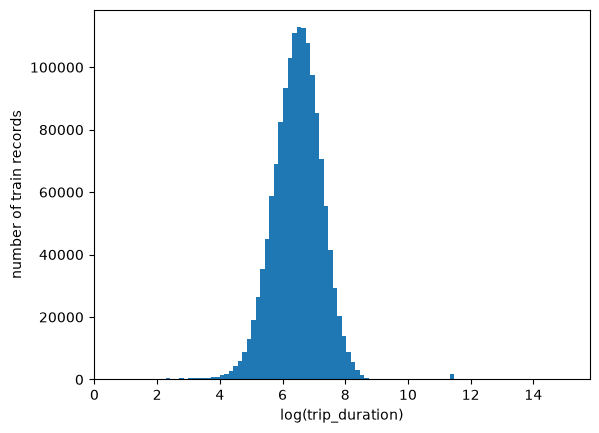

In [14]:
import matplotlib.pyplot as plt


train['log_trip_duration'] = np.log(train['trip_duration'].values + 1)
plt.hist(train['log_trip_duration'].values, bins=100)
plt.xlabel('log(trip_duration)')
plt.ylabel('number of train records')
plt.show()



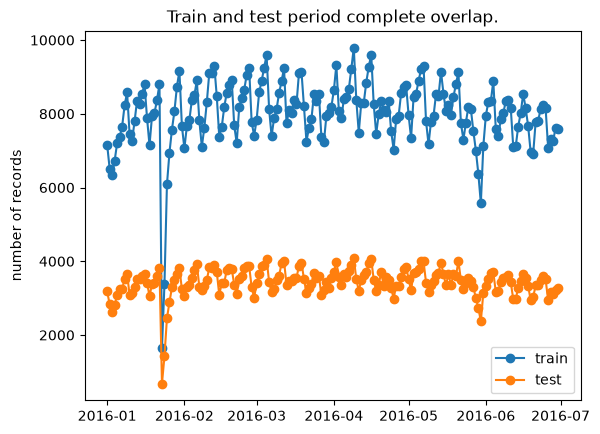

In [15]:


plt.plot(train.groupby('pickup_date').count()[['id']], 'o-', label='train')
plt.plot(test.groupby('pickup_date').count()[['id']], 'o-', label='test')
plt.title('Train and test period complete overlap.')
plt.legend(loc=0)
plt.ylabel('number of records')
plt.show()



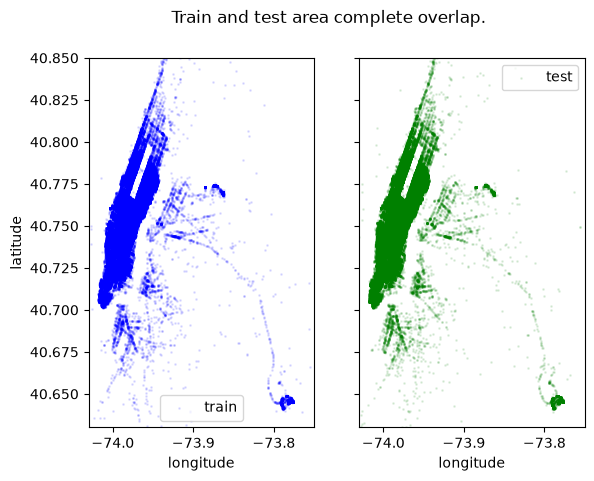

In [18]:


city_long_border = (-74.03, -73.75)
city_lat_border = (40.63, 40.85)
N = min(100_000, len(train), len(test))
fig, ax = plt.subplots(ncols=2, sharex=True, sharey=True)
ax[0].scatter(train['pickup_longitude'].values[:N], train['pickup_latitude'].values[:N],
              color='blue', s=1, label='train', alpha=0.1)
ax[1].scatter(test['pickup_longitude'].values[:N], test['pickup_latitude'].values[:N],
              color='green', s=1, label='test', alpha=0.1)
fig.suptitle('Train and test area complete overlap.')
ax[0].legend(loc=0)
ax[0].set_ylabel('latitude')
ax[0].set_xlabel('longitude')
ax[1].set_xlabel('longitude')
ax[1].legend(loc=0)
plt.ylim(city_lat_border)
plt.xlim(city_long_border)
plt.show()



In [48]:
from sklearn.decomposition import PCA
import pandas as pd
import numpy as np
def datetime_feature_fix(train , test):
    train['pickup_datetime'] = pd.to_datetime(train.pickup_datetime)
    test['pickup_datetime'] = pd.to_datetime(test.pickup_datetime)
    train.loc[:, 'pickup_date'] = train['pickup_datetime'].dt.date
    test.loc[:, 'pickup_date'] = test['pickup_datetime'].dt.date
    train['dropoff_datetime'] = pd.to_datetime(train.dropoff_datetime)
    train['store_and_fwd_flag'] = 1 * (train.store_and_fwd_flag.values == 'Y')
    test['store_and_fwd_flag'] = 1 * (test.store_and_fwd_flag.values == 'Y')
    train['check_trip_duration'] = (train['dropoff_datetime'] - train['pickup_datetime']).map(lambda x: x.total_seconds())
    duration_difference = train[np.abs(train['check_trip_duration'].values  - train['trip_duration'].values) > 1]
    print('Trip_duration and datetimes are ok.') if len(duration_difference[['pickup_datetime', 'dropoff_datetime', 'trip_duration', 'check_trip_duration']]) == 0 else print('Ooops.')

def haversine_array(lat1, lng1, lat2, lng2):
    lat1, lng1, lat2, lng2 = map(np.radians, (lat1, lng1, lat2, lng2))
    AVG_EARTH_RADIUS = 6371  # in km
    lat = lat2 - lat1
    lng = lng2 - lng1
    d = np.sin(lat * 0.5) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin(lng * 0.5) ** 2
    h = 2 * AVG_EARTH_RADIUS * np.arcsin(np.sqrt(d))
    return h

def dummy_manhattan_distance(lat1, lng1, lat2, lng2):
    a = haversine_array(lat1, lng1, lat1, lng2)
    b = haversine_array(lat1, lng1, lat2, lng1)
    return a + b

def bearing_array(lat1, lng1, lat2, lng2):
    AVG_EARTH_RADIUS = 6371  # in km
    lng_delta_rad = np.radians(lng2 - lng1)
    lat1, lng1, lat2, lng2 = map(np.radians, (lat1, lng1, lat2, lng2))
    y = np.sin(lng_delta_rad) * np.cos(lat2)
    x = np.cos(lat1) * np.sin(lat2) - np.sin(lat1) * np.cos(lat2) * np.cos(lng_delta_rad)
    return np.degrees(np.arctan2(y, x))
def create_dis_features(train):


    coords = np.vstack((train[['pickup_latitude', 'pickup_longitude']].values,
                        train[['dropoff_latitude', 'dropoff_longitude']].values,
                        test[['pickup_latitude', 'pickup_longitude']].values,
                        test[['dropoff_latitude', 'dropoff_longitude']].values))

    pca = PCA().fit(coords)
    train['pickup_pca0'] = pca.transform(train[['pickup_latitude', 'pickup_longitude']])[:, 0]
    train['pickup_pca1'] = pca.transform(train[['pickup_latitude', 'pickup_longitude']])[:, 1]
    train['dropoff_pca0'] = pca.transform(train[['dropoff_latitude', 'dropoff_longitude']])[:, 0]
    train['dropoff_pca1'] = pca.transform(train[['dropoff_latitude', 'dropoff_longitude']])[:, 1]
    test['pickup_pca0'] = pca.transform(test[['pickup_latitude', 'pickup_longitude']])[:, 0]
    test['pickup_pca1'] = pca.transform(test[['pickup_latitude', 'pickup_longitude']])[:, 1]
    test['dropoff_pca0'] = pca.transform(test[['dropoff_latitude', 'dropoff_longitude']])[:, 0]
    test['dropoff_pca1'] = pca.transform(test[['dropoff_latitude', 'dropoff_longitude']])[:, 1]


    train.loc[:, 'distance_haversine'] = haversine_array(train['pickup_latitude'].values, train['pickup_longitude'].values, train['dropoff_latitude'].values, train['dropoff_longitude'].values)
    train.loc[:, 'distance_dummy_manhattan'] = dummy_manhattan_distance(train['pickup_latitude'].values, train['pickup_longitude'].values, train['dropoff_latitude'].values, train['dropoff_longitude'].values)
    train.loc[:, 'direction'] = bearing_array(train['pickup_latitude'].values, train['pickup_longitude'].values, train['dropoff_latitude'].values, train['dropoff_longitude'].values)
    train.loc[:, 'pca_manhattan'] = np.abs(train['dropoff_pca1'] - train['pickup_pca1']) + np.abs(train['dropoff_pca0'] - train['pickup_pca0'])

def test_feature_build(train , test ):
    datetime_feature_fix(train , test)
    create_dis_features(train)
    feature_names = [f for f in train.columns]
    feature_names_test = [f for f in test.columns]
    print(f"We have {len(feature_names)} in Traning Data and {len(feature_names_test)} in Testing Data")
    return (train.head() , test.head())

In [49]:
train.head()

,id,vendor_id,pickup_datetime,dropoff_datetime,passenger_count,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,store_and_fwd_flag,trip_duration
0,id2875421,2,2016-03-14 17:24:55,2016-03-14 17:32:30,1,-73.982155,40.767937,-73.964630,40.765602,N,455
1,id2377394,1,2016-06-12 00:43:35,2016-06-12 00:54:38,1,-73.980415,40.738564,-73.999481,40.731152,N,663
2,id3858529,2,2016-01-19 11:35:24,2016-01-19 12:10:48,1,-73.979027,40.763939,-74.005333,40.710087,N,2124
3,id3504673,2,2016-04-06 19:32:31,2016-04-06 19:39:40,1,-74.010040,40.719971,-74.012268,40.706718,N,429
4,id2181028,2,2016-03-26 13:30:55,2016-03-26 13:38:10,1,-73.973053,40.793209,-73.972923,40.782520,N,435


In [55]:
train.info()

<class 'pandas.DataFrame'>
RangeIndex: 5 entries, 0 to 4
Data columns (total 20 columns):
 #   Column                    Non-Null Count  Dtype         
---  ------                    --------------  -----         
 0   vendor_id                 5 non-null      int64         
 1   pickup_datetime           5 non-null      datetime64[us]
 2   dropoff_datetime          5 non-null      datetime64[us]
 3   passenger_count           5 non-null      int64         
 4   pickup_longitude          5 non-null      float64       
 5   pickup_latitude           5 non-null      float64       
 6   dropoff_longitude         5 non-null      float64       
 7   dropoff_latitude          5 non-null      float64       
 8   store_and_fwd_flag        5 non-null      int64         
 9   trip_duration             5 non-null      int64         
 10  pickup_date               5 non-null      object        
 11  check_trip_duration       5 non-null      float64       
 12  pickup_pca0               5 non-null 

In [50]:
train , test = test_feature_build(train=train , test=test)
train = train.drop(columns=['id'])
test = test.drop(columns=['id'])

Trip_duration and datetimes are ok.


/mnt/WindowsD/Artificial Intelligence/genai/lib/python3.14/site-packages/sklearn/utils/validation.py:2820: UserWarning: X has feature names, but PCA was fitted without feature names
  warnings.warn(
/mnt/WindowsD/Artificial Intelligence/genai/lib/python3.14/site-packages/sklearn/utils/validation.py:2820: UserWarning: X has feature names, but PCA was fitted without feature names
  warnings.warn(
/mnt/WindowsD/Artificial Intelligence/genai/lib/python3.14/site-packages/sklearn/utils/validation.py:2820: UserWarning: X has feature names, but PCA was fitted without feature names
  warnings.warn(
/mnt/WindowsD/Artificial Intelligence/genai/lib/python3.14/site-packages/sklearn/utils/validation.py:2820: UserWarning: X has feature names, but PCA was fitted without feature names
  warnings.warn(
/mnt/WindowsD/Artificial Intelligence/genai/lib/python3.14/site-packages/sklearn/utils/validation.py:2820: UserWarning: X has feature names, but PCA was fitted without feature names
  warnings.warn(
/mnt/

We have 21 in Traning Data and 14 in Testing Data


In [17]:
features = {}
for i, idx in train.head(1).iloc[0].to_dict().items():
    features[f'{i}'] = f'input_data.{i}'

In [18]:
features

{'vendor_id': 'input_data.vendor_id',
 'pickup_datetime': 'input_data.pickup_datetime',
 'dropoff_datetime': 'input_data.dropoff_datetime',
 'passenger_count': 'input_data.passenger_count',
 'pickup_longitude': 'input_data.pickup_longitude',
 'pickup_latitude': 'input_data.pickup_latitude',
 'dropoff_longitude': 'input_data.dropoff_longitude',
 'dropoff_latitude': 'input_data.dropoff_latitude',
 'store_and_fwd_flag': 'input_data.store_and_fwd_flag',
 'trip_duration': 'input_data.trip_duration',
 'pickup_date': 'input_data.pickup_date',
 'check_trip_duration': 'input_data.check_trip_duration',
 'pickup_pca0': 'input_data.pickup_pca0',
 'pickup_pca1': 'input_data.pickup_pca1',
 'dropoff_pca0': 'input_data.dropoff_pca0',
 'dropoff_pca1': 'input_data.dropoff_pca1',
 'distance_haversine': 'input_data.distance_haversine',
 'distance_dummy_manhattan': 'input_data.distance_dummy_manhattan',
 'direction': 'input_data.direction',
 'pca_manhattan': 'input_data.pca_manhattan'}

In [20]:
temp = dict(zip(train.columns , train.iloc[1,:]))

In [35]:
f = {}
for k ,  v in temp.items():
    print(f" '{k}' : input_data.{k},")
    f[f" '{k}' "] = f"input_data.{k},"

 'vendor_id' : input_data.vendor_id,
 'pickup_datetime' : input_data.pickup_datetime,
 'dropoff_datetime' : input_data.dropoff_datetime,
 'passenger_count' : input_data.passenger_count,
 'pickup_longitude' : input_data.pickup_longitude,
 'pickup_latitude' : input_data.pickup_latitude,
 'dropoff_longitude' : input_data.dropoff_longitude,
 'dropoff_latitude' : input_data.dropoff_latitude,
 'store_and_fwd_flag' : input_data.store_and_fwd_flag,
 'trip_duration' : input_data.trip_duration,
 'pickup_date' : input_data.pickup_date,
 'check_trip_duration' : input_data.check_trip_duration,
 'pickup_pca0' : input_data.pickup_pca0,
 'pickup_pca1' : input_data.pickup_pca1,
 'dropoff_pca0' : input_data.dropoff_pca0,
 'dropoff_pca1' : input_data.dropoff_pca1,
 'distance_haversine' : input_data.distance_haversine,
 'distance_dummy_manhattan' : input_data.distance_dummy_manhattan,
 'direction' : input_data.direction,
 'pca_manhattan' : input_data.pca_manhattan,


In [31]:
for k ,  v in temp.items():
    print(f'{k} : float')

vendor_id : float
pickup_datetime : float
dropoff_datetime : float
passenger_count : float
pickup_longitude : float
pickup_latitude : float
dropoff_longitude : float
dropoff_latitude : float
store_and_fwd_flag : float
trip_duration : float
pickup_date : float
check_trip_duration : float
pickup_pca0 : float
pickup_pca1 : float
dropoff_pca0 : float
dropoff_pca1 : float
distance_haversine : float
distance_dummy_manhattan : float
direction : float
pca_manhattan : float


In [37]:
f = {
     'vendor_id' : train.vendor_id,
    'pickup_datetime' : train.pickup_datetime,
    'dropoff_datetime' : train.dropoff_datetime,
    'passenger_count' : train.passenger_count,
    'pickup_longitude' : train.pickup_longitude,
    'pickup_latitude' : train.pickup_latitude,
    'dropoff_longitude' : train.dropoff_longitude,
    'dropoff_latitude' : train.dropoff_latitude,
    'store_and_fwd_flag' : train.store_and_fwd_flag,
    'trip_duration' : train.trip_duration,
    'pickup_date' : train.pickup_date,
    'check_trip_duration' : train.check_trip_duration,
    'pickup_pca0' : train.pickup_pca0,
    'pickup_pca1' : train.pickup_pca1,
    'dropoff_pca0' : train.dropoff_pca0,
    'dropoff_pca1' : train.dropoff_pca1,
    'distance_haversine' : train.distance_haversine,
    'distance_dummy_manhattan' : train.distance_dummy_manhattan,
    'direction' : train.direction,
    'pca_manhattan' : train.pca_manhattan,
}

In [41]:
fd = pd.DataFrame(f , index=[0])

In [42]:
fd

,vendor_id,pickup_datetime,dropoff_datetime,passenger_count,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,store_and_fwd_flag,trip_duration,pickup_date,check_trip_duration,pickup_pca0,pickup_pca1,dropoff_pca0,dropoff_pca1,distance_haversine,distance_dummy_manhattan,direction,pca_manhattan
0,2,2016-03-14 17:24:55,2016-03-14 17:32:30,1,-73.982155,40.767937,-73.96463,40.765602,0,455,2016-03-14,455.0,0.028127,-0.003966,0.028149,0.013714,1.498521,1.735433,99.970196,0.017701
